In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [2]:
lena = cv.imread("/Users/miguelcamargorojas/iCloud Drive (Archive)/Documents/UP/PDI-Ago-dic26/PDI-Ago-dic26-Gpo2/images/lena.jpg")

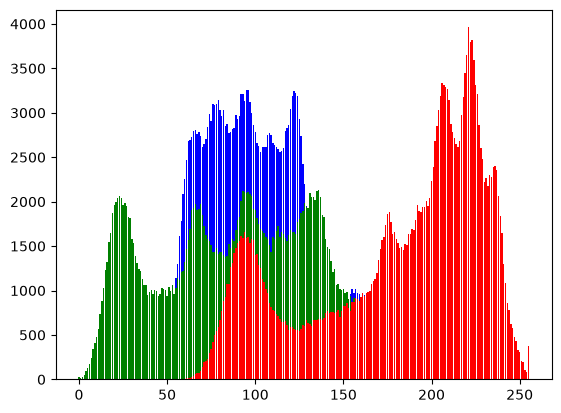

In [5]:
colores = ['b', 'g', 'r']

for i in range(3):
    tmp = cv.calcHist([lena], [i], None, [256], [0, 256])
    plt.bar(range(256), tmp, color=colores[i])
plt.show()

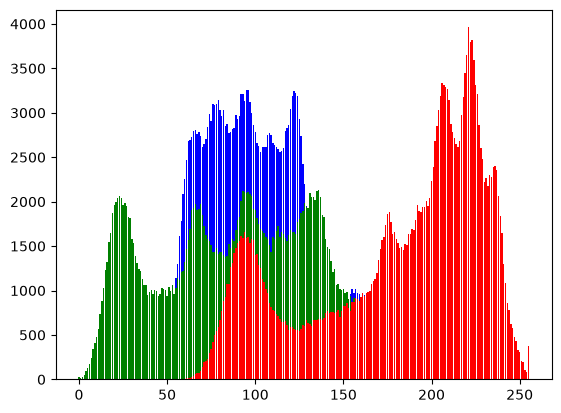

In [6]:
colores = ['b', 'g', 'r']

for n, color in enumerate(colores):
    tmp = cv.calcHist([lena], [n], None, [256], [0, 256])
    plt.bar(range(256), tmp, color=color)
plt.show()

In [11]:
# Esto NO SE HACE 
# No ecualizamos histogramas en RGB/BGR porque aparecen nuevos colores

lena_bgr_eq = lena.copy()

for i in range(3):
    lena_bgr_eq[:, :, i] = cv.equalizeHist(lena[:, :, i])

lena_bgr_eq.shape

(512, 512, 3)

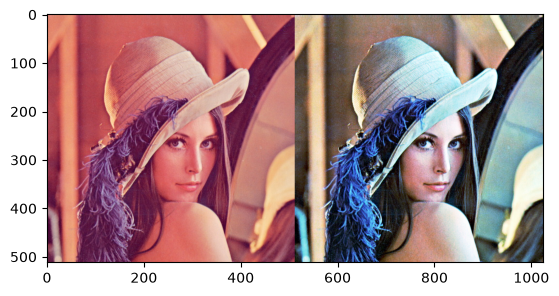

In [13]:
plt.imshow(np.hstack((lena[:, :, ::-1], lena_bgr_eq[:, :, ::-1])))
plt.show()

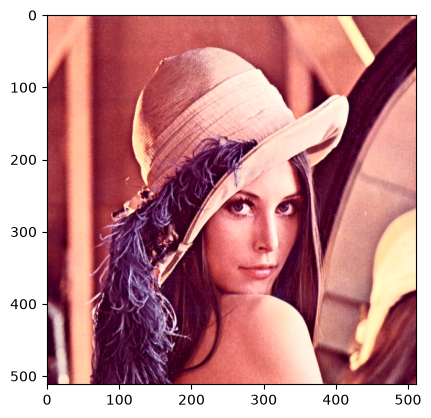

In [15]:
"""
ESTO SÍ HACE

Hay que elegir un espacio de color, en donde uno de los canales guarde la info. de brillo

YCbCr -> Y(luminancia) | CbCr cromas

1) Convertir el espacio de colores de RGB/BGR a YCbCr
2) Separar canales (Y, Cb, Cr)
3) Ecualizar el canal de interés (Y)
4) Unir de vuelta los canales para regresar al espacio anterior (con el canal ecualizado)
5) Regresar al espacio de color original (RGB/BGR)
6) Mostrar el resultado (opcional)
"""

lena_ycrcb = cv.cvtColor(lena, cv.COLOR_BGR2YCrCb) # 1
y, cr, cb = cv.split(lena_ycrcb) # 2
y_eq = cv.equalizeHist(y) # 3
lena_ycrcb_yeq = cv.merge((y_eq, cr, cb)) # 4
lena_rgb_eq = cv.cvtColor(lena_ycrcb_yeq, cv.COLOR_YCrCb2RGB) # 5
plt.imshow(lena_rgb_eq) # 6
plt.show()

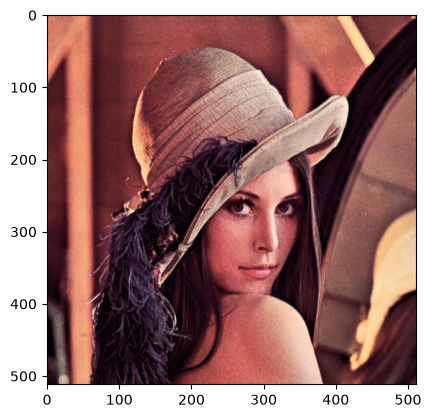

In [16]:
"""
ESTO SÍ HACE

Hay que elegir un espacio de color, en donde uno de los canales guarde la info. de brillo

HSV -> H (Hue), S (Saturation), V(Value) [B Brightness]

1) Convertir el espacio de colores de RGB/BGR a HSV cv.COLOR_BGR2HSV
2) Separar canales (H, S, V)
3) Ecualizar el canal de interés (V)
4) Unir de vuelta los canales para regresar al espacio anterior (con el canal ecualizado)
5) Regresar al espacio de color original (RGB/BGR) cv.COLOR_HSV2RGB
6) Mostrar el resultado (opcional)
"""

lena_hsv = cv.cvtColor(lena, cv.COLOR_BGR2HSV) # 1
h, s, v = cv.split(lena_hsv) # 2
v_eq = cv.equalizeHist(v) # 3
lena_hsv_veq = cv.merge((h, s, v_eq)) # 4
lena_rgb_eq2 = cv.cvtColor(lena_hsv_veq, cv.COLOR_HSV2RGB) # 5
plt.imshow(lena_rgb_eq2) # 6
plt.show()